# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SpaceNet2Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/spacenet_2/train/",
}
dataset = SpaceNet2Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 10592


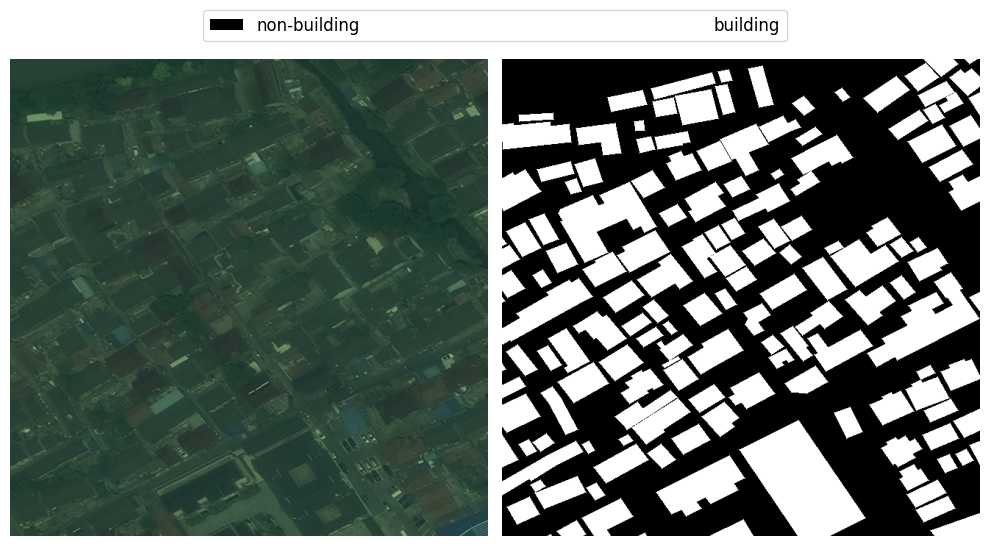

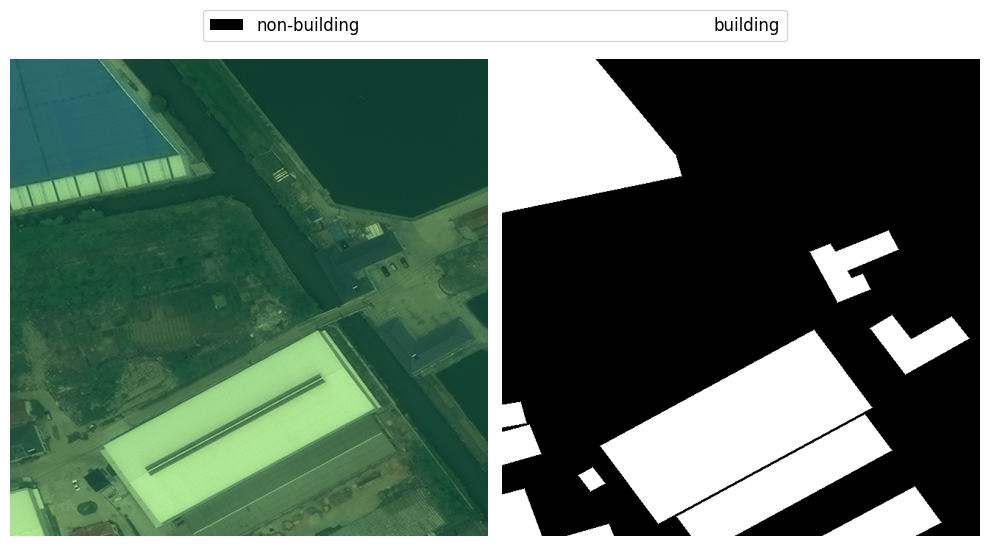

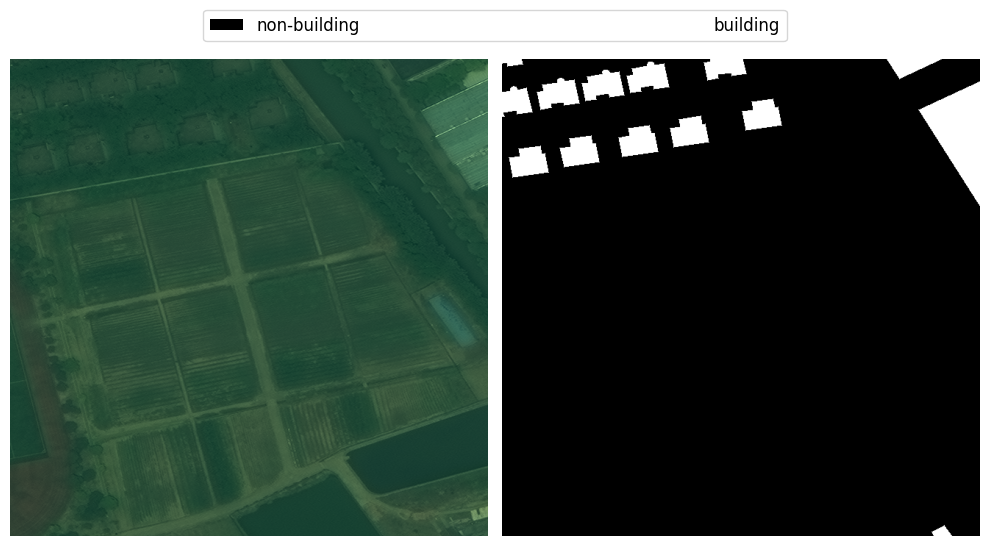

In [53]:
dataset.show_image(200);
dataset.show_image(23);
dataset.show_image(1000);

In [57]:
dataset.data_distribution_table()

,Number of pixels
non-building,3829689899
building,645430101


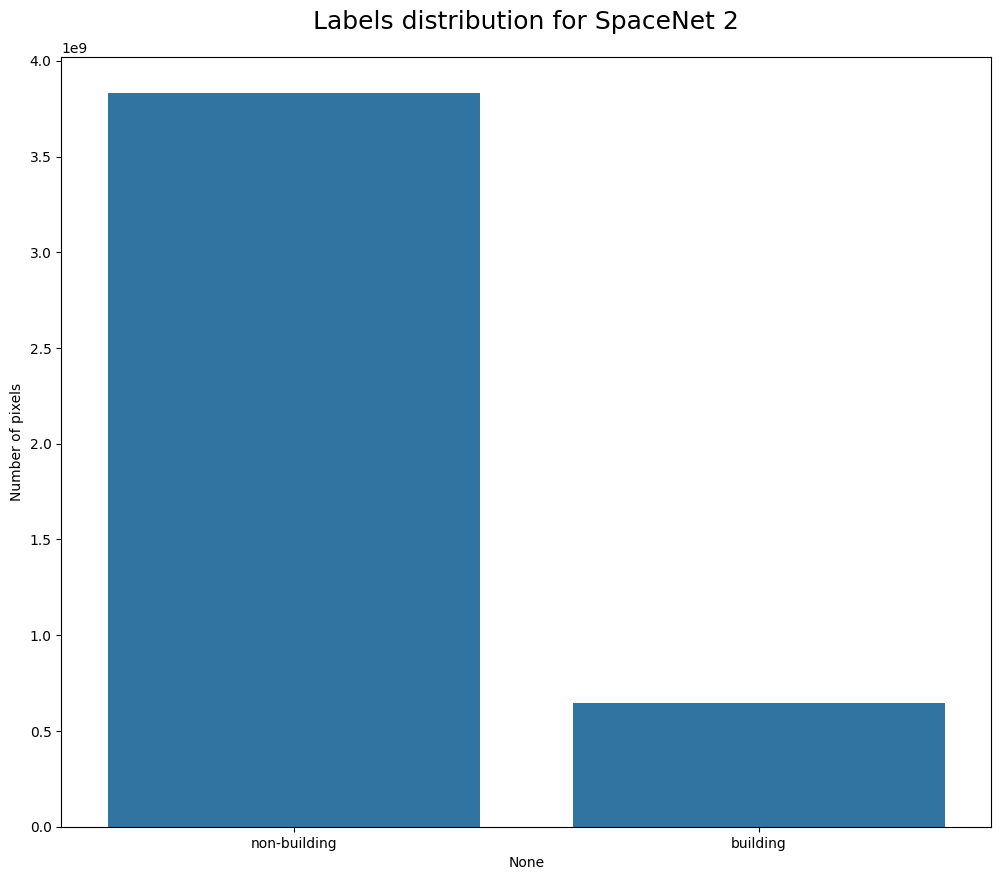

In [58]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/spacenet_2/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SpaceNet2Dataset(train_dataset_config)

len(train_dataset)

10592

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/spacenet_2"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-29 06:29:12,206 INFO Starting training.
training: 100%|██████████| 662/662 [18:31<00:00,  1.68s/it]
2025-09-29 06:47:43,959 INFO epoch: 1, time: 1111, loss:  0.22022
testing on train set: 100%|██████████| 662/662 [18:34<00:00,  1.68s/it]
2025-09-29 07:06:20,373 INFO IOU:0.7733832975024153, IOU mean:0.6623538078023217, IOU per Class:[0.85447832 0.47022929]
training: 100%|██████████| 662/662 [18:57<00:00,  1.72s/it]
2025-09-29 07:25:17,490 INFO epoch: 2, time: 1137, loss:  0.13521
testing on train set: 100%|██████████| 662/662 [18:44<00:00,  1.70s/it]
2025-09-29 07:44:02,433 INFO IOU:0.7967351447141717, IOU mean:0.6925049577559086, IOU per Class:[0.86294419 0.52206573]
training: 100%|██████████| 662/662 [18:19<00:00,  1.66s/it]
2025-09-29 08:02:21,895 INFO epoch: 3, time: 1099, loss:  0.12039
testing on train set: 100%|██████████| 662/662 [18:45<00:00,  1.70s/it]
2025-09-29 08:21:06,972 INFO IOU:0.801691888557535, IOU mean:0.6990186062270338, IOU per Class:[0.86756022 0.53047699]

0.0927761615763258

## Predictions ##

2025-09-29 13:02:18,113 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet2/checkpoint.pth.tar
2025-09-29 13:02:18,590 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet2/checkpoint.pth.tar at epoch 11
2025-09-29 13:02:18,631 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-29 13:02:18,720 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


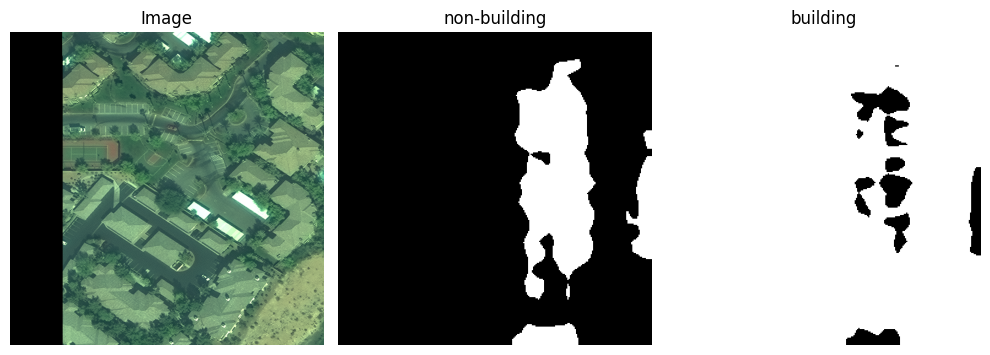

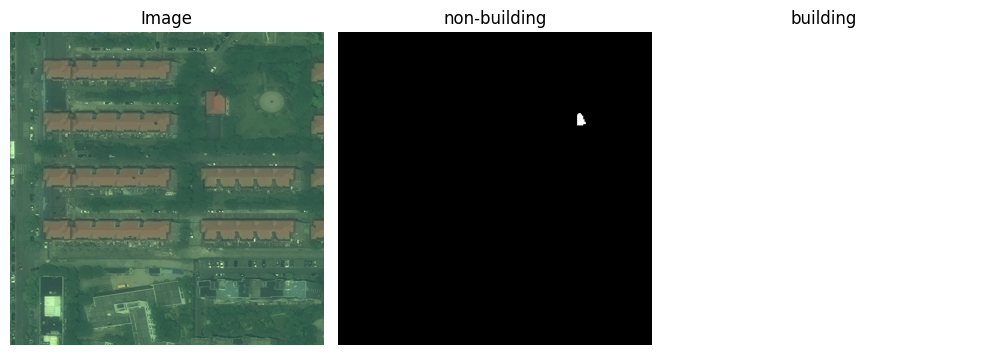

In [ ]:
model_path = "./data/experiments/spacenet_2/checkpoint.pth.tar"
labels = ["non-building","building"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/spacenet_2/test_public/AOI_2_Vegas/PS-RGB/SN2_buildings_test_public_AOI_2_Vegas_PS-RGB_img33.tif').astype(np.float32)/1000
fig = model.predict_masks(image, labels, transform)
image = image_loader('./data/spacenet_2/test_public/AOI_4_Shanghai/PS-RGB/SN2_buildings_test_public_AOI_4_Shanghai_PS-RGB_img276.tif').astype(np.float32)/1000
fig = model.predict_masks(image, labels, transform)